# Pembuktian Citra Digital sebagai Susunan Angka

## 1. Pendahuluan

Citra digital adalah representasi gambar dalam bentuk data numerik yang dapat diproses oleh komputer. Sebuah citra digital tersusun atas elemen-elemen kecil yang disebut piksel (picture element).

Setiap piksel menyimpan informasi tertentu. Pada citra grayscale, setiap piksel umumnya menyimpan satu nilai intensitas keabuan. Sementara itu, pada citra berwarna dengan model RGB, setiap piksel memiliki tiga komponen, yaitu Red (merah), Green (hijau), dan Blue (biru).

Dalam eksperimen ini, Python digunakan untuk membaca sebuah gambar, mengubahnya menjadi array numerik, mengamati nilai piksel, dan membentuk kembali gambar dari array tersebut.

## 2. Tujuan

1. Membuktikan bahwa citra digital direpresentasikan oleh data numerik.
2. Mengetahui dimensi dan jumlah piksel sebuah gambar.
3. Mengidentifikasi nilai RGB pada koordinat piksel tertentu.
4. Mengamati hubungan antara nilai numerik dan tampilan visual gambar.
5. Membuktikan bahwa gambar dapat direkonstruksi dari array numerik.

In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Lokasi gambar
image_path = Path(r"C:\CitraDigital\images\ukhti.jpeg")

# Memastikan file tersedia
if not image_path.exists():
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Periksa folder images "
        "dan nama file ukhti.jpeg."
    )

# Membuka gambar dan mengubahnya menjadi RGB
img = Image.open(image_path).convert("RGB")

# Mengubah gambar menjadi array NumPy
pixels = np.array(img)

print("Gambar berhasil dibaca!")
print("Ukuran gambar (lebar, tinggi):", img.size)
print("Bentuk array:", pixels.shape)
print("Tipe data:", pixels.dtype)
print("Jumlah piksel:", img.width * img.height)
print("Jumlah nilai numerik:", pixels.size)
print("Nilai minimum:", pixels.min())
print("Nilai maksimum:", pixels.max())
  

Gambar berhasil dibaca!
Ukuran gambar (lebar, tinggi): (738, 1600)
Bentuk array: (1600, 738, 3)
Tipe data: uint8
Jumlah piksel: 1180800
Jumlah nilai numerik: 3542400
Nilai minimum: 0
Nilai maksimum: 255


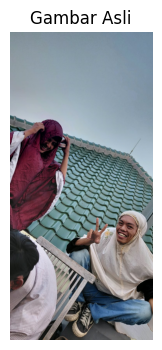

Matriks RGB pada area 5 x 5 piksel:
[[[123 140 147]
  [123 140 147]
  [123 140 147]
  [123 140 147]
  [123 140 147]]

 [[123 140 147]
  [123 140 147]
  [123 140 147]
  [123 140 147]
  [123 140 147]]

 [[124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]]

 [[124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]]

 [[124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]
  [124 141 148]]]


In [3]:

# Menampilkan gambar asli
plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

# Menampilkan matriks RGB dari 5 baris dan 5 kolom pertama
print("Matriks RGB pada area 5 x 5 piksel:")
print(pixels[:5, :5, :])
  

Koordinat piksel: (x=10, y=20)
Nilai RGB: [129 144 151]
Merah (R): 129
Hijau (G): 144
Biru (B): 151


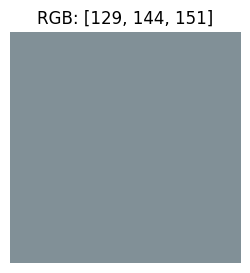

In [4]:

# Koordinat piksel
x, y = 10, 20

# NumPy menggunakan urutan [baris, kolom, kanal]
rgb = pixels[y, x]

print(f"Koordinat piksel: (x={x}, y={y})")
print("Nilai RGB:", rgb)
print("Merah (R):", int(rgb[0]))
print("Hijau (G):", int(rgb[1]))
print("Biru (B):", int(rgb[2]))

# Visualisasi warna dari satu piksel
color_patch = np.zeros((100, 100, 3), dtype=np.uint8)
color_patch[:] = rgb

plt.figure(figsize=(3, 3))
plt.imshow(color_patch)
plt.title(f"RGB: {rgb.tolist()}")
plt.axis("off")
plt.show()
  

## 3. Konversi Citra RGB Menjadi Grayscale

Citra RGB memiliki tiga kanal warna, yaitu merah (Red), hijau (Green), dan biru (Blue). Sementara itu, citra grayscale merepresentasikan setiap piksel menggunakan satu nilai intensitas keabuan.

Konversi ini dapat dilakukan menggunakan rumus pendekatan luminansi:

\[
Y = 0.299R + 0.587G + 0.114B
\]

R, G, dan B merupakan nilai intensitas masing-masing kanal warna, sedangkan Y merupakan nilai intensitas grayscale.

Eksperimen ini bertujuan membuktikan bahwa representasi citra dapat diubah melalui operasi matematis pada nilai-nilai piksel.


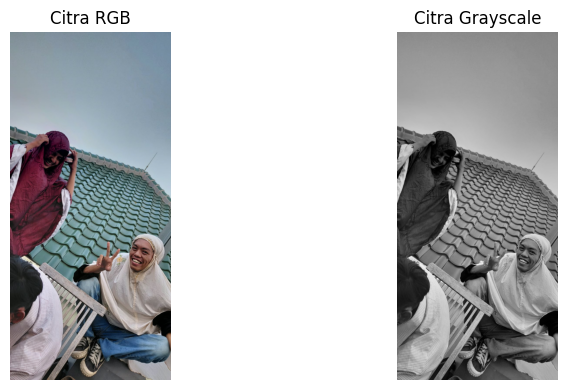

Bentuk array RGB: (1600, 738, 3)
Bentuk array grayscale: (1600, 738)
Contoh nilai grayscale: 140


In [5]:

# Mengambil kanal RGB
R = pixels[:, :, 0].astype(np.float64)
G = pixels[:, :, 1].astype(np.float64)
B = pixels[:, :, 2].astype(np.float64)

# Menghitung intensitas grayscale dengan rumus luminansi
gray_array = np.round(
    0.299 * R + 0.587 * G + 0.114 * B
).clip(0, 255).astype(np.uint8)

# Menampilkan gambar RGB dan grayscale
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(pixels)
ax[0].set_title("Citra RGB")
ax[1].imshow(gray_array, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Citra Grayscale")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Bentuk array RGB:", pixels.shape)
print("Bentuk array grayscale:", gray_array.shape)
print("Contoh nilai grayscale:", gray_array[20, 10])


## 4. Manipulasi Nilai Piksel

Citra digital dapat dimodifikasi melalui operasi aritmetika pada nilai pikselnya. Salah satu contohnya adalah menambahkan konstanta pada intensitas setiap kanal untuk meningkatkan kecerahan gambar.

Pada eksperimen ini, setiap nilai piksel ditambah dengan konstanta 50. Nilai hasil penjumlahan dibatasi hingga 255 karena citra RGB 8-bit memiliki rentang nilai 0 sampai 255.

Eksperimen ini menunjukkan hubungan langsung antara perubahan nilai numerik dan perubahan tampilan citra.

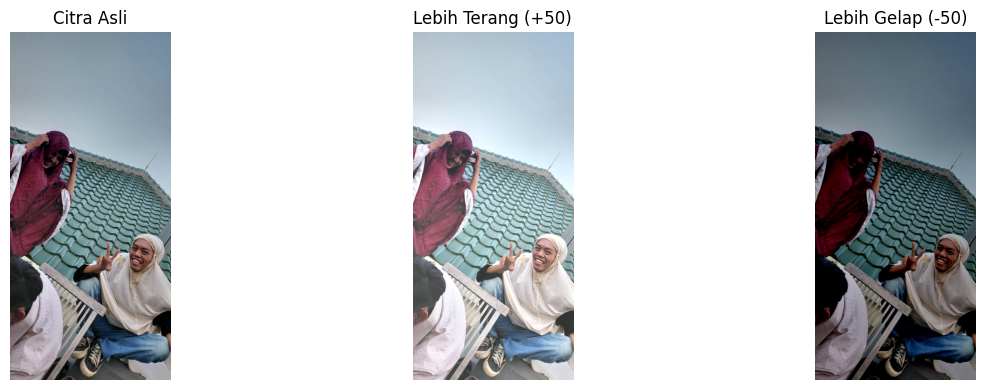

Rata-rata nilai RGB asli: 128.43
Rata-rata RGB lebih terang: 178.0
Rata-rata RGB lebih gelap: 81.75


In [6]:

# Menambah kecerahan setiap kanal sebesar 50
bright_array = np.clip(
    pixels.astype(np.int16) + 50,
    0, 255
).astype(np.uint8)

# Mengurangi kecerahan sebesar 50
dark_array = np.clip(
    pixels.astype(np.int16) - 50,
    0, 255
).astype(np.uint8)

# Membandingkan hasilnya
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].imshow(pixels)
ax[0].set_title("Citra Asli")
ax[1].imshow(bright_array)
ax[1].set_title("Lebih Terang (+50)")
ax[2].imshow(dark_array)
ax[2].set_title("Lebih Gelap (-50)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Rata-rata nilai RGB asli:", round(pixels.mean(), 2))
print("Rata-rata RGB lebih terang:", round(bright_array.mean(), 2))
print("Rata-rata RGB lebih gelap:", round(dark_array.mean(), 2))


## 5. Analisis Histogram Citra

Histogram citra merupakan grafik distribusi frekuensi nilai intensitas piksel. Pada citra grayscale 8-bit, nilai intensitas berkisar antara 0 sampai 255.

Histogram membantu menjelaskan karakteristik distribusi piksel. Nilai yang banyak muncul menunjukkan intensitas yang dominan dalam gambar.

Melalui eksperimen ini, distribusi angka penyusun citra dapat dianalisis secara statistik.

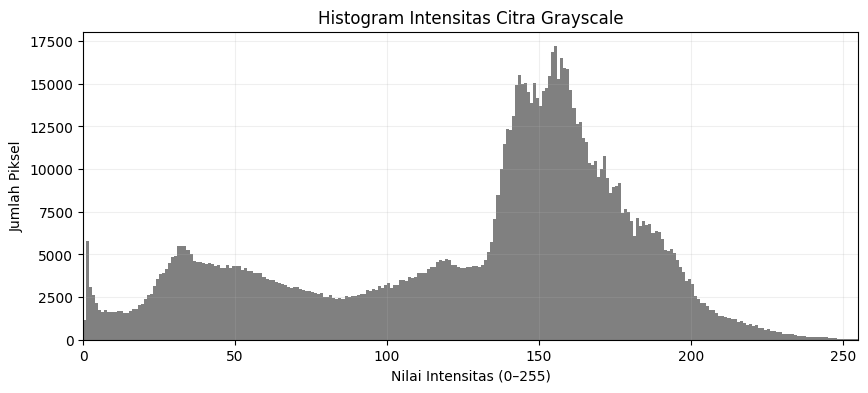

Intensitas minimum: 0
Intensitas maksimum: 255
Rata-rata intensitas: 127.03
Median intensitas: 145.0
Standar deviasi: 54.21


In [7]:
plt.figure(figsize=(10, 4))

plt.hist(
    gray_array.ravel(),
    bins=256,
    range=(0, 256),
    color="gray"
)

plt.title("Histogram Intensitas Citra Grayscale")
plt.xlabel("Nilai Intensitas (0–255)")
plt.ylabel("Jumlah Piksel")
plt.xlim(0, 255)
plt.grid(alpha=0.2)
plt.show()

print("Intensitas minimum:", int(gray_array.min()))
print("Intensitas maksimum:", int(gray_array.max()))
print("Rata-rata intensitas:", round(float(gray_array.mean()), 2))
print("Median intensitas:", float(np.median(gray_array)))
print("Standar deviasi:", round(float(gray_array.std()), 2))

## 6. Rekonstruksi Citra dari Array Numerik

Pada tahap ini, citra dibentuk kembali menggunakan array NumPy yang berisi nilai RGB. Hasil rekonstruksi kemudian dibandingkan dengan array citra asli.

Apabila array sebelum dan sesudah rekonstruksi memiliki nilai yang sama, berarti data numerik tersebut dapat merepresentasikan kembali citra tanpa perubahan nilai piksel pada proses ini.

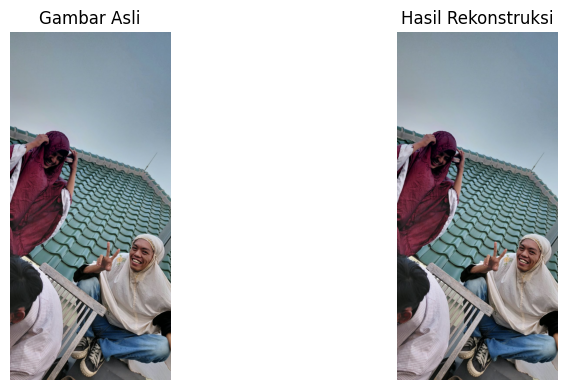

Apakah array identik? True
Jumlah nilai kanal yang berbeda: 0
Perbedaan maksimum: 0


In [8]:

# Membangun kembali citra dari array numerik
reconstructed_img = Image.fromarray(pixels, mode="RGB")
reconstructed_array = np.array(reconstructed_img)

# Memeriksa kesamaan data
identical = np.array_equal(pixels, reconstructed_array)
different_values = int(np.count_nonzero(pixels != reconstructed_array))
max_difference = int(
    np.abs(
        pixels.astype(np.int16) -
        reconstructed_array.astype(np.int16)
    ).max()
)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img)
ax[0].set_title("Gambar Asli")
ax[1].imshow(reconstructed_img)
ax[1].set_title("Hasil Rekonstruksi")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Apakah array identik?", identical)
print("Jumlah nilai kanal yang berbeda:", different_values)
print("Perbedaan maksimum:", max_difference)


In [9]:

from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Menyimpan hasil grayscale, citra terang, dan citra gelap
Image.fromarray(gray_array).save(results_dir / "grayscale.png")
Image.fromarray(bright_array).save(results_dir / "citra_terang.png")
Image.fromarray(dark_array).save(results_dir / "citra_gelap.png")

# Menyimpan hasil rekonstruksi
reconstructed_img.save(results_dir / "rekonstruksi.png")

print("Semua hasil eksperimen berhasil disimpan.")
print("Lokasi hasil:", results_dir.resolve())


Semua hasil eksperimen berhasil disimpan.
Lokasi hasil: C:\Citra-Digital\results


## 7. Kesimpulan

Berdasarkan eksperimen yang telah dilakukan, citra digital dapat direpresentasikan sebagai susunan data numerik. Pada citra RGB, setiap piksel memiliki tiga komponen nilai intensitas, yaitu merah, hijau, dan biru, yang umumnya berkisar antara 0 sampai 255 untuk representasi 8-bit.

Hasil pengolahan menunjukkan bahwa nilai-nilai numerik tersebut dapat ditampilkan sebagai matriks, dikonversi menjadi grayscale, dimanipulasi untuk mengubah kecerahan, dan dianalisis menggunakan histogram. Selain itu, citra dapat direkonstruksi dari array numerik dengan nilai piksel yang identik.

Dengan demikian, eksperimen ini mendukung pembuktian bahwa citra digital merupakan representasi numerik yang dapat diolah menggunakan operasi matematika dan pemrograman komputer.